# Semana 06 — Benchmark de procesamiento de datos en entorno local
## Pandas vs. PySpark con datos sintéticos y RT-IoT2022

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ)  
**Docente:** Leibnihtz Abrahan Ayamamani Choque  
**Semestre:** 2026-2  
**Etapa del flujo:** 03 — Análisis

---

### Propósito

Comparar Pandas y PySpark con cargas equivalentes, interpretar el costo de cada motor y construir un flujo reproducible con capas **Bronze → Silver → Gold**.

### Al finalizar podrás

1. verificar si el equipo está preparado para ejecutar Spark localmente;
2. descargar y perfilar un dataset real de tráfico IoT;
3. medir tiempo y memoria con Pandas y PySpark;
4. transformar datos entre las capas Bronze, Silver y Gold;
5. justificar qué herramienta conviene según la escala del problema.

> **Alcance:** el notebook conserva el benchmark original. Solo se acondicionó el inicio al flujo EDA 2026-2 y se aislaron los archivos temporales del experimento.

---
## 0. Preparación reproducible

Antes de analizar datos verificaremos cuatro dependencias del experimento:

1. la raíz del proyecto EDA;
2. Java 17, requerido por PySpark;
3. los paquetes de Python;
4. los recursos disponibles y la sesión local de Spark.

Los archivos generados se guardarán en `tmp/semana05_benchmark/`. Así evitamos mezclar resultados desechables del benchmark con los datos oficiales de `data/bronze`, `data/silver` y `data/gold`.

> Ejecuta las celdas en orden. Si una verificación falla, resuelve ese requisito antes de continuar.

In [1]:
# Paso 0.1: localizar el proyecto y verificar Java
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Busca la raíz del proyecto EDA desde la ubicación actual."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").exists() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto EDA. Abre Jupyter desde el repositorio "
        "o cambia el directorio de trabajo a una carpeta dentro de él."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks" / "03_analysis"

print(f"Proyecto : {PROJECT_ROOT}")
print(f"Notebook : {NOTEBOOK_DIR}")
print(f"Python   : {sys.version.split()[0]}")
print(f"Sistema  : {platform.system()} {platform.release()}")

java = shutil.which("java")
if java is None:
    raise RuntimeError(
        "Java no está disponible en PATH. Instala JDK 17, reinicia Jupyter/VS Code "
        "y vuelve a ejecutar esta celda."
    )

result = subprocess.run([java, "-version"], capture_output=True, text=True, check=False)
java_version = (result.stderr or result.stdout).splitlines()[0]
print(f"Java     : {java_version}")

Proyecto : C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA
Notebook : C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\notebooks\03_analysis
Python   : 3.12.10
Sistema  : Windows 11
Java     : openjdk version "17.0.18" 2026-01-20


In [2]:
# Paso 0.2: preparar un espacio aislado para el benchmark
BENCHMARK_DIR = PROJECT_ROOT / "tmp" / "semana05_benchmark"
RT_IOT_DIR = BENCHMARK_DIR / "rt_iot2022"
DATA_LAKE_IOT = BENCHMARK_DIR / "data_lake_iot"
DATA_LAKE_SYNTH = BENCHMARK_DIR / "data_lake"

for path in (RT_IOT_DIR, DATA_LAKE_IOT, DATA_LAKE_SYNTH):
    path.mkdir(parents=True, exist_ok=True)

# El notebook original usa algunas rutas relativas. Trabajar dentro de esta
# carpeta conserva esas celdas sin dispersar archivos por el repositorio.
os.chdir(BENCHMARK_DIR)

print("Carpetas del laboratorio listas:")
print(f"  Dataset RT-IoT2022 : {RT_IOT_DIR}")
print(f"  Data Lake IoT      : {DATA_LAKE_IOT}")
print(f"  Data Lake sintético: {DATA_LAKE_SYNTH}")

Carpetas del laboratorio listas:
  Dataset RT-IoT2022 : C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\rt_iot2022
  Data Lake IoT      : C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot
  Data Lake sintético: C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake


In [3]:
# Paso 0.3: configurar el entorno local y los helpers de Parquet
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)

# En Windows, un HADOOP_HOME incompleto puede impedir escrituras locales.
hadoop_home = os.environ.get("HADOOP_HOME")
if platform.system() == "Windows" and hadoop_home:
    winutils = Path(hadoop_home) / "bin" / "winutils.exe"
    if not winutils.exists():
        os.environ.pop("HADOOP_HOME", None)
        print("Aviso: se ignoró HADOOP_HOME porque no contiene bin/winutils.exe")

import pandas as pd


def write_parquet_dir_local(pdf: pd.DataFrame, path) -> Path:
    """Escribe un DataFrame de Pandas como una carpeta Parquet."""
    path = Path(path)
    if path.exists():
        if path.is_dir():
            shutil.rmtree(path)
        else:
            path.unlink()
    path.mkdir(parents=True, exist_ok=True)
    pdf.to_parquet(path / "part-00000.parquet", index=False)
    return path


def write_spark_parquet_local(df_sp, path) -> Path:
    """Materializa un resultado Spark pequeño o mediano en Parquet local."""
    return write_parquet_dir_local(df_sp.toPandas(), path)


def read_parquet_local(path) -> pd.DataFrame:
    """Lee una carpeta creada por write_parquet_dir_local."""
    return pd.read_parquet(Path(path))


def tag_from_scale(nombre: str) -> str:
    """Convierte una etiqueta de escala en un nombre de carpeta estable."""
    import re

    texto = str(nombre).strip().lower()
    match = re.search(r"(full|\d+\s*[km])\s*$", texto)
    if match:
        return match.group(1).replace(" ", "")
    texto = re.sub(r"^[^0-9a-zA-Z]+", "", texto)
    return texto.strip().replace(" ", "")


print("Entorno local configurado")
print(f"  PYSPARK_PYTHON: {os.environ['PYSPARK_PYTHON']}")
print(f"  HADOOP_HOME    : {os.environ.get('HADOOP_HOME', '(no definido)')}")

Entorno local configurado
  PYSPARK_PYTHON: c:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\BigData20262\Scripts\python.exe
  HADOOP_HOME    : (no definido)


In [4]:
# Paso 0.4: verificar los paquetes antes de iniciar el benchmark
import importlib.util
from packaging.version import Version

REQUIRED_PACKAGES = [
    "pandas", "numpy", "matplotlib", "psutil", "pyspark", "kaggle", "pyarrow"
]
missing = [pkg for pkg in REQUIRED_PACKAGES if importlib.util.find_spec(pkg) is None]

if missing:
    packages = " ".join(missing)
    raise ModuleNotFoundError(
        f"Faltan paquetes: {', '.join(missing)}. Instálalos en el entorno activo con: "
        f"python -m pip install {packages}"
    )


import pandas as pd
if Version(pd.__version__) >= Version("3.0.0"):
    raise RuntimeError(
        f"Pandas {pd.__version__} no es compatible con este flujo de PySpark. "
        "Instala una versión 2.x con: python -m pip install 'pandas>=2.2.3,<3.0' "
        "y reinicia el kernel."
    )

print(f"Paquetes disponibles | Pandas {pd.__version__} (< 3.0, compatible)")

Paquetes disponibles | Pandas 2.3.3 (< 3.0, compatible)


In [5]:
# ── Paso 0.5: verificar recursos disponibles en local ────────────────────
import psutil

ram_gb    = psutil.virtual_memory().total  / 1024**3
ram_disp  = psutil.virtual_memory().available / 1024**3
cpu_count = os.cpu_count()

print("═" * 45)
print(f"  RAM total disponible : {ram_gb:.2f} GB")
print(f"  RAM libre ahora      : {ram_disp:.2f} GB")
print(f"  CPUs disponibles     : {cpu_count}")
print("═" * 45)
print()
print("📌 Estos recursos definen el 'techo' de Pandas.")
print("   Cuando el dataset supere la RAM libre, Pandas")
print("   empezará a degradarse. PySpark usa disco + RAM.")


═════════════════════════════════════════════
  RAM total disponible : 15.71 GB
  RAM libre ahora      : 6.35 GB
  CPUs disponibles     : 12
═════════════════════════════════════════════

📌 Estos recursos definen el 'techo' de Pandas.
   Cuando el dataset supere la RAM libre, Pandas
   empezará a degradarse. PySpark usa disco + RAM.


In [6]:
# Paso 0.6: iniciar una sesión Spark local
from pyspark.sql import SparkSession

try:
    spark.stop()
except NameError:
    pass

spark = (
    SparkSession.builder
    .appName("Semana05_Benchmark_EDA")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")
print("Sesión Spark local iniciada")
print(f"  Versión: {spark.version}")

Sesión Spark local iniciada
  Versión: 4.2.0


### Credenciales de Kaggle

El dataset real se descarga mediante la API de Kaggle. Antes de continuar:

1. entra a Kaggle → **Settings** → **API** → **Create New Token**;
2. guarda `kaggle.json` en `C:\Users\TU_USUARIO\.kaggle\kaggle.json` (Windows) o `~/.kaggle/kaggle.json` (macOS/Linux);
3. acepta las condiciones del dataset en Kaggle si la plataforma lo solicita.

> **Seguridad:** no pegues el usuario ni la clave en una celda y no agregues `kaggle.json` al repositorio.

---
## 0-B. RT-IoT2022: descarga, carga y benchmark

### Contexto del dataset

RT-IoT2022 reúne tráfico de dispositivos IoT físicos como ThingSpeak-LED, MQTT-Temp, Wipro-Bulb, Amazon Alexa y Raspberry Pi. Incluye tráfico normal y ataques como fuerza bruta SSH, DDoS y Nmap.

| Propiedad | Valor aproximado |
|---|---:|
| Tamaño del CSV | 50 MB |
| Filas | 120 000 flujos |
| Variables | 41 características y una etiqueta |
| Licencia | CC BY 4.0 |

**Pregunta guía:** ¿la ventaja de un motor distribuido aparece con cualquier volumen o depende del tamaño y del costo de inicialización?

In [7]:
# Celda B.1: validar el token de Kaggle sin exponer secretos
KAGGLE_DIR = Path.home() / ".kaggle"
KAGGLE_JSON = KAGGLE_DIR / "kaggle.json"

if not KAGGLE_JSON.is_file():
    raise FileNotFoundError(
        f"No se encontró {KAGGLE_JSON}. Descarga kaggle.json desde Kaggle y "
        "guárdalo en esa ruta antes de continuar."
    )

try:
    os.chmod(KAGGLE_JSON, 0o600)
except (OSError, PermissionError):
    pass

print(f"Token de Kaggle disponible en: {KAGGLE_JSON}")

Token de Kaggle disponible en: C:\Users\Leibnihtz\.kaggle\kaggle.json


In [8]:
# ?? Celda B.2: descargar el dataset con Kaggle CLI ??????????????????????
import os, subprocess, time
from pathlib import Path

DATASET_SLUG = "supplejade/rt-iot2022real-time-internet-of-things"
DEST_DIR = RT_IOT_DIR
CSV_PATH = DEST_DIR / "RT_IOT2022.csv"
DEST_DIR.mkdir(parents=True, exist_ok=True)

if CSV_PATH.exists():
    size_mb = CSV_PATH.stat().st_size / 1024**2
    print(f"? Dataset ya descargado ({size_mb:.1f} MB) ? saltando descarga.")
else:
    print("??  Descargando RT-IoT2022 (~50 MB)...")
    t0 = time.time()
    cmd = ["kaggle", "datasets", "download", "-d", DATASET_SLUG, "--path", str(DEST_DIR), "--unzip", "-q"]
    result = subprocess.run(cmd, capture_output=True, text=True)
    elapsed = time.time() - t0

    if result.returncode != 0:
        raise RuntimeError(
            "Descarga fallida. Verifica token Kaggle, aceptaci?n de reglas del dataset y conexión."
            + result.stderr
        )

    csvs = list(DEST_DIR.glob("*.csv"))
    if not csvs:
        raise FileNotFoundError(f"No se encontr? CSV en {DEST_DIR}. Archivos: {list(DEST_DIR.iterdir())}")

    actual = csvs[0]
    if actual.name != "RT_IOT2022.csv":
        actual.rename(CSV_PATH)
        print(f"Renombrado: {actual.name} -> RT_IOT2022.csv")

    size_mb = CSV_PATH.stat().st_size / 1024**2
    print(f"? Descarga completada en {elapsed:.1f}s ? {size_mb:.1f} MB")

CSV_PATH = str(CSV_PATH)
print(f"CSV listo en: {CSV_PATH}")


? Dataset ya descargado (52.2 MB) ? saltando descarga.
CSV listo en: C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\rt_iot2022\RT_IOT2022.csv


In [9]:
# ── Celda B.3: inspección inicial del dataset ────────────────────────────
import pandas as pd

print('🔍 Cargando RT-IoT2022 para inspección...')
df_raw = pd.read_csv(CSV_PATH)

N_TOTAL = len(df_raw)
N_COLS  = len(df_raw.columns)

print()
print('═' * 55)
print('  RT-IoT2022 — INSPECCIÓN INICIAL')
print('═' * 55)
print(f'  Filas totales  : {N_TOTAL:,}')
print(f'  Columnas       : {N_COLS}')
print(f'  RAM en Pandas  : {df_raw.memory_usage(deep=True).sum()/1024**2:.1f} MB')

label_col = 'Attack_type' if 'Attack_type' in df_raw.columns else df_raw.columns[-1]
print()
print(f"  Distribución de tráfico ('{label_col}'):")
dist = df_raw[label_col].value_counts()
for lbl, cnt in dist.items():
    pct = cnt / N_TOTAL * 100
    bar = '█' * int(pct / 2)
    print(f'    {str(lbl):<30} {cnt:>6,}  {pct:>5.1f}%  {bar}')
print('═' * 55)
print()
df_raw.head(3)


🔍 Cargando RT-IoT2022 para inspección...

═══════════════════════════════════════════════════════
  RT-IoT2022 — INSPECCIÓN INICIAL
═══════════════════════════════════════════════════════
  Filas totales  : 123,117
  Columnas       : 85
  RAM en Pandas  : 96.3 MB

  Distribución de tráfico ('Attack_type'):
    DOS_SYN_Hping                  94,659   76.9%  ██████████████████████████████████████
    Thing_Speak                     8,108    6.6%  ███
    ARP_poisioning                  7,750    6.3%  ███
    MQTT_Publish                    4,146    3.4%  █
    NMAP_UDP_SCAN                   2,590    2.1%  █
    NMAP_XMAS_TREE_SCAN             2,010    1.6%  
    NMAP_OS_DETECTION               2,000    1.6%  
    NMAP_TCP_scan                   1,002    0.8%  
    DDOS_Slowloris                    534    0.4%  
    Wipro_bulb                        253    0.2%  
    Metasploit_Brute_Force_SSH         37    0.0%  
    NMAP_FIN_SCAN                      28    0.0%  
══════════════════════

,no,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish


In [10]:
# ?? Celda B.4: crear las 4 escalas en Bronze ?????????????????????????????
import os, gc
from pathlib import Path

ESCALAS_IOT = {
    "S1 ? 30K" :  30_000,
    "S2 ? 60K" :  60_000,
    "S3 ? 90K" :  90_000,
    "S4 ? Full":  N_TOTAL,
}
ESCALAS_IOT = {k: min(v, N_TOTAL) for k, v in ESCALAS_IOT.items()}

BRONZE_BASE = DATA_LAKE_IOT
sample_paths = {}

print(f"Dataset base: {N_TOTAL:,} filas")
print()

for nombre, n in ESCALAS_IOT.items():
    tag = tag_from_scale(nombre)
    if tag == "full":
        tag = str(N_TOTAL)
    bronze_dir = BRONZE_BASE / tag / "bronze"
    bronze_dir.mkdir(parents=True, exist_ok=True)
    csv_out = bronze_dir / "rt_iot2022.csv"

    sample = df_raw.copy() if n == N_TOTAL else df_raw.sample(n=n, random_state=42).reset_index(drop=True)
    sample.to_csv(csv_out, index=False)

    kb = csv_out.stat().st_size / 1024
    sample_paths[nombre] = str(csv_out)
    print(f"  ? {nombre:<12}  {n:>7,} filas  ({kb:.0f} KB)  ->  {csv_out}")

    del sample; gc.collect()

del df_raw; gc.collect()
print()
print("? 4 escalas guardadas en Bronze.")


Dataset base: 123,117 filas

  ? S1 ? 30K       30,000 filas  (12671 KB)  ->  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\30k\bronze\rt_iot2022.csv
  ? S2 ? 60K       60,000 filas  (25310 KB)  ->  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\60k\bronze\rt_iot2022.csv
  ? S3 ? 90K       90,000 filas  (37971 KB)  ->  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\90k\bronze\rt_iot2022.csv
  ? S4 ? Full     123,117 filas  (51936 KB)  ->  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\123117\bronze\rt_iot2022.csv

? 4 escalas guardadas en Bronze.


In [11]:
# ?? Celda B.5: inspeccionar Bronze con Python local ?????????????????????
from pathlib import Path

print("Estructura Bronze ? vista local:")
print("?" * 50)
for path in sorted(DATA_LAKE_IOT.glob("*/bronze/rt_iot2022.csv")):
    size_mb = path.stat().st_size / 1024**2
    print(f"{size_mb:8.2f} MB  {path}")

print()
print("Primeras 2 l?neas del CSV S1:")
with open(sample_paths["S1 ? 30K"], "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i >= 2:
            break
        print(" ", line.strip()[:120], "..." if len(line) > 120 else "")


Estructura Bronze ? vista local:
??????????????????????????????????????????????????
   50.72 MB  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\123117\bronze\rt_iot2022.csv
   12.37 MB  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\30k\bronze\rt_iot2022.csv
   24.72 MB  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\60k\bronze\rt_iot2022.csv
   37.08 MB  C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake_iot\90k\bronze\rt_iot2022.csv

Primeras 2 l?neas del CSV S1:
  no,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkt ...
  55444,7315,21,tcp,-,1e-06,1,1,1,0,838860.8,838860.8,1677721.6,1.0,20,20,20,20,20,20,0,1,1,0,0,1,0,0,0,0,120.0,120.0,120. ...


In [12]:
# ?? Celda B.6: funciones de benchmark adaptadas a RT-IoT2022 ?????????????
#
# El dataset IoT tiene columnas distintas a los logs simulados.
# Algunas columnas tienen puntos en el nombre, por ejemplo fwd_pkts_payload.avg.
# En Spark esos nombres deben escaparse con backticks.

import pandas as pd, numpy as np
import time, tracemalloc, gc, os, psutil
from pyspark.sql.functions import col, avg, count


def spark_col(nombre: str):
    """Devuelve una columna Spark escapada; soporta nombres con puntos."""
    return col(f"`{nombre}`")


# Detectar columnas autom?ticamente
_s = pd.read_csv(list(sample_paths.values())[0], nrows=1)
LABEL_COL   = "Attack_type" if "Attack_type" in _s.columns else _s.columns[-1]
PROTO_COL   = "proto"       if "proto"       in _s.columns else "service"
DUR_COL     = "flow_duration"
NUM_COLS    = _s.select_dtypes(include="number").columns.tolist()[:10]
PAYLOAD_COL = "fwd_pkts_payload.avg" if "fwd_pkts_payload.avg" in _s.columns else NUM_COLS[5]
del _s

print(f"Columnas detectadas -> label: {LABEL_COL} | proto: {PROTO_COL} | dur: {DUR_COL}")
print(f"Payload col: {PAYLOAD_COL}")
print(f"Primeras 10 numericas para Op3: {NUM_COLS}")


def benchmark_pandas_iot(csv_path: str) -> dict:
    r = {}

    tracemalloc.start()
    t0 = time.perf_counter()
    df = pd.read_csv(csv_path)
    t1 = time.perf_counter()
    _, ram = tracemalloc.get_traced_memory(); tracemalloc.stop()
    r["carga_s"]  = round(t1 - t0, 3)
    r["carga_mb"] = round(ram / 1024**2, 2)

    tracemalloc.start()
    t0 = time.perf_counter()
    _ = df.groupby(PROTO_COL)[DUR_COL].count()
    t1 = time.perf_counter()
    _, ram = tracemalloc.get_traced_memory(); tracemalloc.stop()
    r["groupby_s"]  = round(t1 - t0, 3)
    r["groupby_mb"] = round(ram / 1024**2, 2)

    tracemalloc.start()
    t0 = time.perf_counter()
    _ = df[df[DUR_COL] > 0].groupby(LABEL_COL)[NUM_COLS].mean()
    t1 = time.perf_counter()
    _, ram = tracemalloc.get_traced_memory(); tracemalloc.stop()
    r["filtro_agg_s"]  = round(t1 - t0, 3)
    r["filtro_agg_mb"] = round(ram / 1024**2, 2)

    resumen  = df.groupby(LABEL_COL)[DUR_COL].agg(["mean", "count"]).reset_index()
    gold_file = csv_path.replace("bronze", "gold").replace(".csv", "_pandas.csv")
    os.makedirs(os.path.dirname(gold_file), exist_ok=True)
    t0 = time.perf_counter()
    resumen.to_csv(gold_file, index=False)
    t1 = time.perf_counter()
    r["escritura_s"] = round(t1 - t0, 3)

    r["total_s"]   = round(sum(v for k, v in r.items() if k.endswith("_s")), 3)
    r["ram_df_mb"] = round(df.memory_usage(deep=True).sum() / 1024**2, 2)
    r["n"] = len(df)
    del df, resumen; gc.collect()
    return r


def benchmark_pyspark_iot(csv_path: str) -> dict:
    r = {}
    proc = psutil.Process(os.getpid())

    ram_antes = proc.memory_info().rss / 1024**2
    t0 = time.perf_counter()
    df_sp = spark.read.option("header", True).option("inferSchema", True).csv(csv_path)
    df_sp.cache(); _ = df_sp.count()
    t1 = time.perf_counter()
    r["carga_s"]  = round(t1 - t0, 3)
    r["carga_mb"] = round(max(proc.memory_info().rss / 1024**2 - ram_antes, 0), 2)

    t0 = time.perf_counter()
    _ = df_sp.groupBy(spark_col(PROTO_COL)).agg(count(spark_col(DUR_COL)).alias("total")).collect()
    t1 = time.perf_counter()
    r["groupby_s"] = round(t1 - t0, 3)

    t0 = time.perf_counter()
    _ = (df_sp
         .filter(spark_col(DUR_COL) > 0)
         .groupBy(spark_col(LABEL_COL))
         .agg(
             avg(spark_col(DUR_COL)).alias("avg_duration"),
             avg(spark_col(PAYLOAD_COL)).alias("avg_payload"),
             count("*").alias("total")
         )
         .collect())
    t1 = time.perf_counter()
    r["filtro_agg_s"] = round(t1 - t0, 3)

    # Windows local: se materializa el resultado peque?o con Pandas para evitar dependencia de winutils.exe.
    resumen = df_sp.groupBy(spark_col(LABEL_COL)).agg(
        avg(spark_col(DUR_COL)).alias("avg_dur"),
        count("*").alias("total")
    )
    gold_file = csv_path.replace("bronze", "gold").replace(".csv", "_spark.csv")
    os.makedirs(os.path.dirname(gold_file), exist_ok=True)
    t0 = time.perf_counter()
    resumen.toPandas().to_csv(gold_file, index=False)
    t1 = time.perf_counter()
    r["escritura_s"] = round(t1 - t0, 3)

    r["total_s"] = round(sum(v for k, v in r.items() if k.endswith("_s")), 3)
    r["n"] = df_sp.count()
    df_sp.unpersist()
    return r


print("\n? benchmark_pandas_iot() y benchmark_pyspark_iot() listas.")


Columnas detectadas -> label: Attack_type | proto: proto | dur: flow_duration
Payload col: fwd_pkts_payload.avg
Primeras 10 numericas para Op3: ['no', 'id.orig_p', 'id.resp_p', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec']

? benchmark_pandas_iot() y benchmark_pyspark_iot() listas.


In [13]:
# ── Celda B.7: ejecutar benchmark completo IoT ───────────────────────────

resultados_pandas_iot = {}
resultados_spark_iot  = {}

print('Benchmark RT-IoT2022 — datos reales de dispositivos IoT')
print('─' * 65)

for nombre, csv_path in sample_paths.items():
    n = ESCALAS_IOT[nombre]

    print(f'  ⏳ Pandas  {nombre:<12} ({n:>7,} filas) ...', end='', flush=True)
    rp = benchmark_pandas_iot(csv_path)
    resultados_pandas_iot[nombre] = rp
    print(f'  ✅ {rp["total_s"]:.2f}s  RAM: {rp["ram_df_mb"]:.0f} MB')

    print(f'  ⏳ PySpark {nombre:<12} ({n:>7,} filas) ...', end='', flush=True)
    rs = benchmark_pyspark_iot(csv_path)
    resultados_spark_iot[nombre] = rs
    print(f'  ✅ {rs["total_s"]:.2f}s')
    print()

print('─' * 65)
print('✅ Benchmark IoT completado.')


Benchmark RT-IoT2022 — datos reales de dispositivos IoT
─────────────────────────────────────────────────────────────────
  ⏳ Pandas  S1 ? 30K     ( 30,000 filas) ...  ✅ 0.34s  RAM: 23 MB
  ⏳ PySpark S1 ? 30K     ( 30,000 filas) ...  ✅ 10.57s

  ⏳ Pandas  S2 ? 60K     ( 60,000 filas) ...  ✅ 0.70s  RAM: 47 MB
  ⏳ PySpark S2 ? 60K     ( 60,000 filas) ...  ✅ 2.53s

  ⏳ Pandas  S3 ? 90K     ( 90,000 filas) ...  ✅ 1.00s  RAM: 70 MB
  ⏳ PySpark S3 ? 90K     ( 90,000 filas) ...  ✅ 2.33s

  ⏳ Pandas  S4 ? Full    (123,117 filas) ...  ✅ 1.44s  RAM: 96 MB
  ⏳ PySpark S4 ? Full    (123,117 filas) ...  ✅ 2.18s

─────────────────────────────────────────────────────────────────
✅ Benchmark IoT completado.


In [14]:
# ── Celda B.8: resumen y tabla comparativa final ─────────────────────────

nombres_iot = list(ESCALAS_IOT.keys())

rows = []
for nombre in nombres_iot:
    p = resultados_pandas_iot[nombre]
    s = resultados_spark_iot[nombre]
    ratio   = round(s['total_s'] / p['total_s'], 2) if p['total_s'] > 0 else 0
    ganador = 'PySpark ✅' if s['total_s'] < p['total_s'] else 'Pandas  ✅'
    rows.append({
        'Escala'         : nombre,
        'Filas'          : f"{p['n']:,}",
        'Pandas (s)'     : p['total_s'],
        'PySpark (s)'    : s['total_s'],
        'Ratio (S/P)'    : ratio,
        'Ganador'        : ganador,
        'RAM Pandas (MB)': p['ram_df_mb'],
    })

import pandas as pd
df_res = pd.DataFrame(rows)

print('═' * 75)
print('  RT-IoT2022 BENCHMARK — RESULTADO FINAL')
print('═' * 75)
print(df_res.to_string(index=False))
print('═' * 75)
print()
print('📌 Para usar las 5 gráficas de la Parte 5 con estos datos,')
print('   sustituye en cada celda de graficación:')
print('   - resultados_pandas  →  resultados_pandas_iot')
print('   - resultados_spark   →  resultados_spark_iot')
print('   - ESCALAS            →  ESCALAS_IOT')
print('   - escalas_labels     →  ["S1\\n30K","S2\\n60K","S3\\n90K","S4\\nFull"]')


═══════════════════════════════════════════════════════════════════════════
  RT-IoT2022 BENCHMARK — RESULTADO FINAL
═══════════════════════════════════════════════════════════════════════════
   Escala   Filas  Pandas (s)  PySpark (s)  Ratio (S/P)   Ganador  RAM Pandas (MB)
 S1 ? 30K  30,000       0.345       10.566        30.63 Pandas  ✅            23.47
 S2 ? 60K  60,000       0.704        2.534         3.60 Pandas  ✅            46.95
 S3 ? 90K  90,000       1.001        2.330         2.33 Pandas  ✅            70.42
S4 ? Full 123,117       1.435        2.183         1.52 Pandas  ✅            96.33
═══════════════════════════════════════════════════════════════════════════

📌 Para usar las 5 gráficas de la Parte 5 con estos datos,
   sustituye en cada celda de graficación:
   - resultados_pandas  →  resultados_pandas_iot
   - resultados_spark   →  resultados_spark_iot
   - ESCALAS            →  ESCALAS_IOT
   - escalas_labels     →  ["S1\n30K","S2\n60K","S3\n90K","S4\nFull"]


---
## Gold IoT — métricas sobre datos reales

Las siguientes celdas generan las métricas Gold usando
el dataset completo (S4). Son el equivalente IoT real
de la Parte 4 del notebook de benchmark original.

---


In [15]:
# ?? Celda B.9: m?tricas Gold del Data Lake IoT ???????????????????????????
from pyspark.sql.functions import col, avg, count, countDistinct, when, sum as spark_sum


def spark_col(nombre: str):
    """Permite usar en Spark columnas con puntos en el nombre."""
    return col(f"`{nombre}`")


csv_full = sample_paths["S4 ? Full"]
df_iot = spark.read.option("header", True).option("inferSchema", True).csv(csv_full)

df_silver_iot = (df_iot
    .filter(spark_col(DUR_COL) > 0)
    .filter(spark_col(PROTO_COL).isNotNull())
    .dropDuplicates())

silver_path = DATA_LAKE_IOT / "silver_iot"
silver_iot_count = df_silver_iot.count()
write_spark_parquet_local(df_silver_iot, silver_path)
print(f"Silver IoT: {silver_iot_count:,} registros guardados en Parquet local")

kpi1 = (df_silver_iot
    .groupBy(spark_col(LABEL_COL))
    .agg(count("*").alias("total"))
    .orderBy("total", ascending=False))
kpi1.show(truncate=False)

kpi2 = (df_silver_iot
    .groupBy(spark_col(LABEL_COL))
    .agg(
        avg(spark_col(DUR_COL)).alias("avg_duration_s"),
        avg(spark_col(PAYLOAD_COL)).alias("avg_payload_bytes")
    )
    .orderBy("avg_duration_s", ascending=False))
kpi2.show(truncate=False)

kpi3 = (df_silver_iot
    .groupBy(spark_col(PROTO_COL))
    .agg(count("*").alias("flujos"), avg(spark_col(DUR_COL)).alias("dur_promedio"))
    .orderBy("flujos", ascending=False)
    .limit(10))
kpi3.show(truncate=False)

gold_iot = DATA_LAKE_IOT / "gold"
write_spark_parquet_local(kpi1, gold_iot / "kpi1_ataque_tipo")
write_spark_parquet_local(kpi2, gold_iot / "kpi2_duracion_tipo")
write_spark_parquet_local(kpi3, gold_iot / "kpi3_top_protocolos")
print("\n? 3 KPIs Gold IoT guardados en Parquet local.")


Silver IoT: 107,136 registros guardados en Parquet local
+--------------------------+-----+
|Attack_type               |total|
+--------------------------+-----+
|DOS_SYN_Hping             |83797|
|Thing_Speak               |7932 |
|ARP_poisioning            |5294 |
|MQTT_Publish              |4139 |
|NMAP_OS_DETECTION         |2000 |
|NMAP_XMAS_TREE_SCAN       |1998 |
|NMAP_TCP_scan             |1002 |
|DDOS_Slowloris            |531  |
|Wipro_bulb                |244  |
|NMAP_UDP_SCAN             |160  |
|Metasploit_Brute_Force_SSH|35   |
|NMAP_FIN_SCAN             |4    |
+--------------------------+-----+

+--------------------------+---------------------+--------------------+
|Attack_type               |avg_duration_s       |avg_payload_bytes   |
+--------------------------+---------------------+--------------------+
|Wipro_bulb                |608.4916759631149    |52.348873959016416  |
|MQTT_Publish              |43.470407666586155   |7.926638256825407   |
|ARP_poisioning       

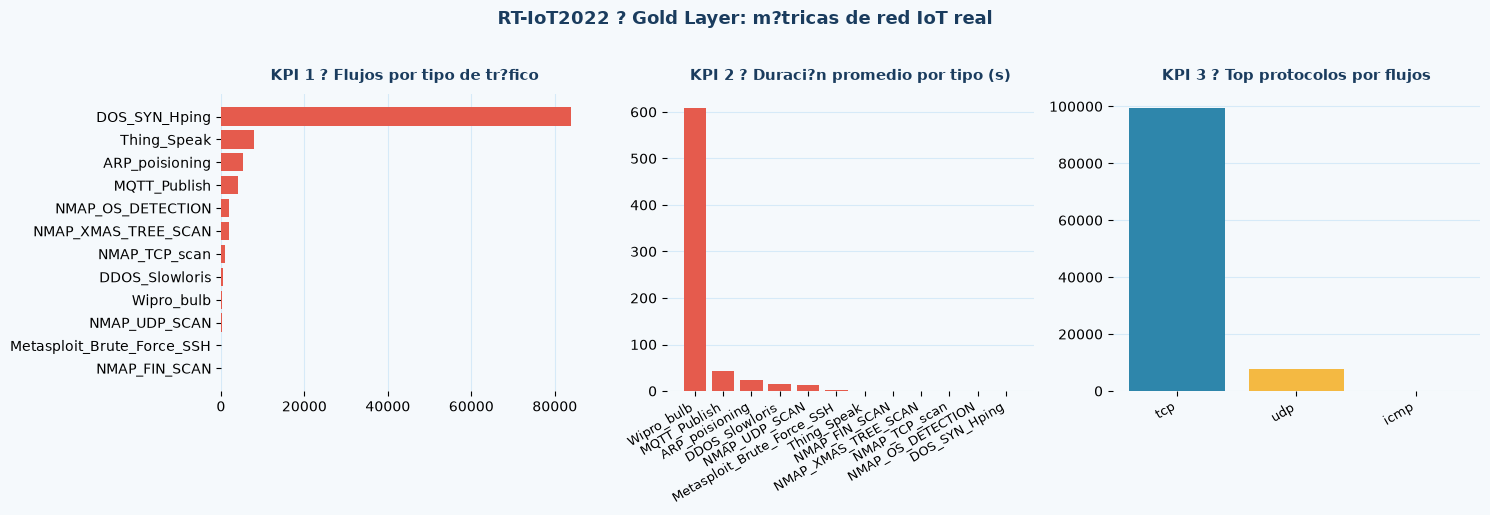

?? Estos KPIs vienen de dispositivos IoT reales: ThingSpeak-LED, MQTT-Temp, Wipro-Bulb.


In [16]:
# ?? Celda B.10: visualizar KPIs Gold con Matplotlib ?????????????????????
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

C_NAVY   = '#1A3C5E'
C_STEEL  = '#2E86AB'
C_CORAL  = '#E55B4D'
C_GOLD   = '#F4B942'
C_GREEN  = '#27AE60'
C_BG     = '#F5F9FC'

kpi1_pd = read_parquet_local(DATA_LAKE_IOT / 'gold' / 'kpi1_ataque_tipo')
kpi2_pd = read_parquet_local(DATA_LAKE_IOT / 'gold' / 'kpi2_duracion_tipo')
kpi3_pd = read_parquet_local(DATA_LAKE_IOT / 'gold' / 'kpi3_top_protocolos')

kpi1_pd = kpi1_pd.sort_values('total', ascending=True)
kpi3_pd = kpi3_pd.sort_values('flujos', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(C_BG)

colores_tipo = [C_STEEL if 'normal' in str(v).lower() or 'benign' in str(v).lower() else C_CORAL
                for v in kpi1_pd[LABEL_COL]]

# Gr?fica 1: tasa de ataque por tipo
ax = axes[0]; ax.set_facecolor(C_BG)
ax.barh(kpi1_pd[LABEL_COL].astype(str), kpi1_pd['total'], color=colores_tipo, zorder=3)
ax.set_title('KPI 1 ? Flujos por tipo de tr?fico', fontsize=11, color=C_NAVY, fontweight='bold', pad=10)
ax.xaxis.grid(True, color='#D6EAF8', zorder=0); ax.set_axisbelow(True)
ax.spines[['top','right','left','bottom']].set_visible(False)

# Gr?fica 2: duraci?n promedio por tipo
ax = axes[1]; ax.set_facecolor(C_BG)
kpi2_pd = kpi2_pd.sort_values('avg_duration_s', ascending=False)
colores_dur = [C_CORAL if 'normal' not in str(v).lower() and 'benign' not in str(v).lower() else C_STEEL
               for v in kpi2_pd[LABEL_COL]]
ax.bar(kpi2_pd[LABEL_COL].astype(str), kpi2_pd['avg_duration_s'].astype(float),
       color=colores_dur, zorder=3)
ax.set_xticklabels(kpi2_pd[LABEL_COL].astype(str), rotation=30, ha='right', fontsize=9)
ax.set_title('KPI 2 ? Duraci?n promedio por tipo (s)', fontsize=11, color=C_NAVY, fontweight='bold', pad=10)
ax.yaxis.grid(True, color='#D6EAF8', zorder=0); ax.set_axisbelow(True)
ax.spines[['top','right','left','bottom']].set_visible(False)

# Gr?fica 3: top protocolos
ax = axes[2]; ax.set_facecolor(C_BG)
palette = [C_STEEL, C_GOLD, C_CORAL, C_GREEN, '#9B59B6', C_NAVY, '#E67E22', '#1ABC9C', '#E74C3C', '#3498DB']
ax.bar(kpi3_pd[PROTO_COL].astype(str)[:8], kpi3_pd['flujos'][:8],
       color=palette[:len(kpi3_pd[:8])], zorder=3)
ax.set_xticklabels(kpi3_pd[PROTO_COL].astype(str)[:8], rotation=30, ha='right', fontsize=9)
ax.set_title('KPI 3 ? Top protocolos por flujos', fontsize=11, color=C_NAVY, fontweight='bold', pad=10)
ax.yaxis.grid(True, color='#D6EAF8', zorder=0); ax.set_axisbelow(True)
ax.spines[['top','right','left','bottom']].set_visible(False)

plt.suptitle('RT-IoT2022 ? Gold Layer: m?tricas de red IoT real',
             fontsize=13, color=C_NAVY, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('grafica_gold_iot_real.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()
print('?? Estos KPIs vienen de dispositivos IoT reales: ThingSpeak-LED, MQTT-Temp, Wipro-Bulb.')


---


# 🧪 Benchmark complementario con dataset sintético universitario

La primera mitad del notebook trabajó con **RT-IoT2022**, un dataset real descargado desde Kaggle.

Desde aquí continúa el laboratorio original con datos sintéticos generados en local.  
Esto permite comparar dos enfoques didácticos:

- **Datos reales:** mayor autenticidad, requiere Kaggle API.
- **Datos sintéticos:** reproducibles, controlados y útiles para explicar escalabilidad paso a paso.


---
## PARTE 1 · Generar los datasets por escala

Creamos un **generador reproducible** de logs digitales universitarios.
El mismo generador produce los 4 tamaños con `np.random.seed(42)` para que los resultados sean comparables.

Cada evento simula una interacción real de un estudiante con la plataforma LMS de la UNAJ:

| Campo | Descripción |
|-------|-------------|
| `event_id` | Identificador único del evento |
| `user_id` | ID del estudiante (anonimizado) |
| `session_id` | ID de sesión de navegación |
| `event_type` | Tipo de acción (login, search, view_content, etc.) |
| `event_time` | Timestamp del evento |
| `device` | Dispositivo usado (mobile, desktop, tablet) |
| `country` | País de origen |
| `course_id` | Curso relacionado |
| `response_time_ms` | Tiempo de respuesta del servidor (ms) |
| `status_code` | Código HTTP de respuesta |
| `event_date` | Fecha del evento (para particionado) |


In [17]:
# ── Paso 1.1: función generadora de logs ─────────────────────────────────
import pandas as pd
import numpy as np
import os, gc, time

ESCALAS = {
    "S1 · 1M":   1_000_000,
    "S2 · 5M":   5_000_000,
    "S3 · 10M":   10_000_000,
    "S4 · 20M":   20_000_000,
}

EVENT_TYPES = ["login","search","view_content","download_file",
               "submit_quiz","logout","error"]
EVENT_PROBS = [0.12, 0.18, 0.32, 0.12, 0.08, 0.13, 0.05]
DEVICES     = ["mobile","desktop","tablet"]
COUNTRIES   = ["PE","CO","MX","CL","AR"]
PAGES       = ["home","course","content","quiz","forum","profile"]
STATUS_CODES = [200, 201, 400, 404, 500]
STATUS_PROBS = [0.80, 0.05, 0.05, 0.05, 0.05]

def generar_logs(n: int) -> pd.DataFrame:
    """Genera n eventos de log reproducibles con seed=42."""
    np.random.seed(42)
    df = pd.DataFrame({
        "event_id"        : np.arange(1, n + 1),
        "user_id"         : np.random.randint(10000, 99999, n),
        "session_id"      : np.random.randint(100000, 999999, n),
        "event_type"      : np.random.choice(EVENT_TYPES, n, p=EVENT_PROBS),
        "event_time"      : pd.date_range("2026-04-01", periods=n, freq="s"),
        "device"          : np.random.choice(DEVICES, n),
        "country"         : np.random.choice(COUNTRIES, n),
        "page"            : np.random.choice(PAGES, n),
        "course_id"       : np.random.randint(100, 999, n),
        "response_time_ms": np.random.exponential(scale=300, size=n).round(0),
        "status_code"     : np.random.choice(STATUS_CODES, n, p=STATUS_PROBS),
    })
    df["event_date"] = df["event_time"].dt.date.astype(str)
    return df

print("✅ Generador definido")
print(f"   Escalas planificadas: {list(ESCALAS.keys())}")


✅ Generador definido
   Escalas planificadas: ['S1 · 1M', 'S2 · 5M', 'S3 · 10M', 'S4 · 20M']


In [18]:
# ?? Paso 1.2: crear estructura de carpetas del Data Lake ?????????????????
from pathlib import Path

for escala in ESCALAS:
    tag = tag_from_scale(escala)
    for capa in ["bronze", "silver", "gold"]:
        (DATA_LAKE_SYNTH / tag / capa / "events").mkdir(parents=True, exist_ok=True)

print("? Estructura Data Lake creada")
for i, path in enumerate(sorted(DATA_LAKE_SYNTH.rglob("*"))):
    if path.is_dir():
        print(path)
    if i >= 20:
        break


? Estructura Data Lake creada
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\100k
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\100k\bronze
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\100k\bronze\events
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\100k\gold
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\100k\gold\events
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\100k\silver
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\100k\silver\events
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\10m
C:\Users\Leibnihtz\Documents\Leibtechs\D

---
## PARTE 2 · Benchmark con Pandas

Para cada escala ejecutamos **4 operaciones estándar** y medimos tiempo y RAM:

1. **Carga** del CSV desde disco
2. **Agrupación** por `event_type` (conteo)
3. **Filtro + agregación** (promedio de `response_time_ms` por `device`)
4. **Escritura** de resultados a CSV

> 💡 **Observa:** a medida que N crece, ¿qué le pasa al tiempo? ¿Y a la RAM? ¿Crece linealmente o de otra forma?


In [19]:
# ── Paso 2.1: función de benchmark Pandas ────────────────────────────────
import tracemalloc

def benchmark_pandas(n: int, tag: str) -> dict:
    """
    Genera, guarda y procesa n eventos con Pandas.
    Devuelve dict con tiempos y RAM por operación.
    """
    resultados = {}

    # ── Generar y guardar CSV Bronze ──────────────────────────────────────
    df = generar_logs(n)
    csv_path = f"data_lake/{tag}/bronze/events/logs.csv"
    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    df.to_csv(csv_path, index=False)
    del df; gc.collect()

    # ── Op 1: Carga ───────────────────────────────────────────────────────
    tracemalloc.start()
    t0 = time.perf_counter()
    df = pd.read_csv(csv_path)
    t1 = time.perf_counter()
    _, ram_carga = tracemalloc.get_traced_memory(); tracemalloc.stop()
    resultados["carga_s"]   = round(t1 - t0, 3)
    resultados["carga_mb"]  = round(ram_carga / 1024**2, 2)

    # ── Op 2: Agrupación ──────────────────────────────────────────────────
    tracemalloc.start()
    t0 = time.perf_counter()
    _ = df.groupby("event_type")["event_id"].count()
    t1 = time.perf_counter()
    _, ram_group = tracemalloc.get_traced_memory(); tracemalloc.stop()
    resultados["groupby_s"]  = round(t1 - t0, 3)
    resultados["groupby_mb"] = round(ram_group / 1024**2, 2)

    # ── Op 3: Filtro + agregación ─────────────────────────────────────────
    tracemalloc.start()
    t0 = time.perf_counter()
    _ = df[df["status_code"] == 200].groupby("device")["response_time_ms"].mean()
    t1 = time.perf_counter()
    _, ram_agg = tracemalloc.get_traced_memory(); tracemalloc.stop()
    resultados["filtro_agg_s"]  = round(t1 - t0, 3)
    resultados["filtro_agg_mb"] = round(ram_agg / 1024**2, 2)

    # ── Op 4: Escritura resultado ─────────────────────────────────────────
    out = df.groupby("event_type")["event_id"].count().reset_index()
    gold_csv_path = f"data_lake/{tag}/gold/events/resumen_pandas.csv"
    os.makedirs(os.path.dirname(gold_csv_path), exist_ok=True)
    tracemalloc.start()
    t0 = time.perf_counter()
    out.to_csv(gold_csv_path, index=False)
    t1 = time.perf_counter()
    _, ram_write = tracemalloc.get_traced_memory(); tracemalloc.stop()
    resultados["escritura_s"]  = round(t1 - t0, 3)
    resultados["escritura_mb"] = round(ram_write / 1024**2, 2)

    # ── Total ─────────────────────────────────────────────────────────────
    resultados["total_s"]  = round(sum(v for k,v in resultados.items() if k.endswith("_s")), 3)
    resultados["ram_df_mb"] = round(df.memory_usage(deep=True).sum() / 1024**2, 2)
    resultados["n"] = n

    del df; gc.collect()
    return resultados

print("✅ Función benchmark_pandas() lista")


✅ Función benchmark_pandas() lista


In [20]:
# ── Paso 2.2: ejecutar benchmark Pandas en las 4 escalas ─────────────────
resultados_pandas = {}

print("Ejecutando benchmark Pandas...")
print("─" * 60)

for nombre, n in ESCALAS.items():
    tag = tag_from_scale(nombre)
    print(f"  ⏳ {nombre:15s}  ({n:>9,} eventos) ...", end="", flush=True)
    r = benchmark_pandas(n, tag)
    resultados_pandas[nombre] = r
    print(f"  ✅  {r['total_s']:.2f}s  |  RAM DataFrame: {r['ram_df_mb']:.0f} MB")

print("─" * 60)
print("✅ Benchmark Pandas completado")


Ejecutando benchmark Pandas...
────────────────────────────────────────────────────────────
  ⏳ S1 · 1M          (1,000,000 eventos) ...  ✅  4.46s  |  RAM DataFrame: 376 MB
  ⏳ S2 · 5M          (5,000,000 eventos) ...  ✅  15.56s  |  RAM DataFrame: 1878 MB
  ⏳ S3 · 10M         (10,000,000 eventos) ...  ✅  31.61s  |  RAM DataFrame: 3756 MB
  ⏳ S4 · 20M         (20,000,000 eventos) ...  ✅  54.68s  |  RAM DataFrame: 7512 MB
────────────────────────────────────────────────────────────
✅ Benchmark Pandas completado


In [21]:
# ── Paso 2.3: tabla resumen Pandas ───────────────────────────────────────
rows = []
for nombre, r in resultados_pandas.items():
    rows.append({
        "Escala"          : nombre,
        "Eventos"         : f"{r['n']:,}",
        "Carga (s)"       : r["carga_s"],
        "GroupBy (s)"     : r["groupby_s"],
        "Filtro+Agg (s)"  : r["filtro_agg_s"],
        "Escritura (s)"   : r["escritura_s"],
        "TOTAL (s)"       : r["total_s"],
        "RAM DataFrame MB": r["ram_df_mb"],
    })

df_resumen_pandas = pd.DataFrame(rows)
print("═" * 80)
print("  PANDAS — RESUMEN DE BENCHMARK")
print("═" * 80)
print(df_resumen_pandas.to_string(index=False))
print("═" * 80)
print()
print("📌 ¿Qué observas? Anota tu hipótesis antes de ver los resultados de PySpark.")


════════════════════════════════════════════════════════════════════════════════
  PANDAS — RESUMEN DE BENCHMARK
════════════════════════════════════════════════════════════════════════════════
  Escala    Eventos  Carga (s)  GroupBy (s)  Filtro+Agg (s)  Escritura (s)  TOTAL (s)  RAM DataFrame MB
 S1 · 1M  1,000,000      4.148        0.102           0.208          0.003      4.461            375.58
 S2 · 5M  5,000,000     14.617        0.300           0.638          0.005     15.560           1877.91
S3 · 10M 10,000,000     29.679        0.600           1.329          0.003     31.611           3755.79
S4 · 20M 20,000,000     49.993        1.399           3.256          0.028     54.676           7511.58
════════════════════════════════════════════════════════════════════════════════

📌 ¿Qué observas? Anota tu hipótesis antes de ver los resultados de PySpark.


---
### 📝 Pausa de reflexión — antes de PySpark

Antes de continuar, responde estas preguntas en la celda de texto siguiente:

1. ¿El tiempo de Pandas creció de forma lineal con el número de eventos?
2. ¿Qué operación fue la más costosa en tiempo?
3. ¿Cuánta RAM ocupa el DataFrame de 2M eventos?
4. ¿Qué pasaría si el dataset fuera de 20M eventos y tu laptop tiene solo 8 GB de RAM?
5. ¿Cuál es tu hipótesis: PySpark será más rápido en S1 (100K)? ¿Y en S4 (2M)?


**✏️ Escribe aquí tu hipótesis antes de ejecutar la Parte 3:**

*(Doble clic para editar)*

- Tiempo Pandas en S4: ______ segundos
- RAM Pandas en S4: ______ MB
- Hipótesis PySpark vs Pandas en S1: ______
- Hipótesis PySpark vs Pandas en S4: ______


---
## PARTE 3 · Benchmark con PySpark

Ejecutamos **las mismas 4 operaciones** sobre **los mismos datos** usando PySpark.

> 🔑 **Diferencia clave:** PySpark no carga todo en RAM de golpe. Trabaja con un **DAG de transformaciones** (grafo dirigido acíclico) que ejecuta en particiones. El costo de inicialización es mayor, pero el costo por operación escala mejor.

Lo que medirás:
- **Carga** del CSV particionado
- **Agrupación** distribuida por `event_type`
- **Filtro + agregación** por `device`
- **Escritura** en formato **Parquet** (columnar, comprimido)


In [22]:
# ── Paso 3.1: función de benchmark PySpark ───────────────────────────────
from pyspark.sql.functions import col, avg, count, to_timestamp

def benchmark_pyspark(n: int, tag: str) -> dict:
    """
    Procesa n eventos desde Bronze con PySpark.
    Devuelve dict con tiempos por operación.
    Nota: tracemalloc no captura memoria JVM.
    Usamos psutil para medir RAM del proceso completo.
    """
    resultados = {}
    csv_path = f"data_lake/{tag}/bronze/events/logs.csv"
    proc = psutil.Process(os.getpid())

    # ── Op 1: Carga ───────────────────────────────────────────────────────
    ram_antes = proc.memory_info().rss / 1024**2
    t0 = time.perf_counter()
    df_sp = spark.read.option("header", True).option("inferSchema", True).csv(csv_path)
    df_sp.cache()
    _ = df_sp.count()   # fuerza materialización
    t1 = time.perf_counter()
    ram_despues = proc.memory_info().rss / 1024**2
    resultados["carga_s"]  = round(t1 - t0, 3)
    resultados["carga_mb"] = round(max(ram_despues - ram_antes, 0), 2)

    # ── Op 2: Agrupación ──────────────────────────────────────────────────
    t0 = time.perf_counter()
    _ = df_sp.groupBy("event_type").agg(count("event_id").alias("total")).collect()
    t1 = time.perf_counter()
    resultados["groupby_s"] = round(t1 - t0, 3)

    # ── Op 3: Filtro + agregación ─────────────────────────────────────────
    t0 = time.perf_counter()
    _ = df_sp.filter(col("status_code") == 200) \
             .groupBy("device") \
             .agg(avg("response_time_ms").alias("avg_ms")) \
             .collect()
    t1 = time.perf_counter()
    resultados["filtro_agg_s"] = round(t1 - t0, 3)

    # ── Op 4: Escritura Parquet ───────────────────────────────────────────
    resumen = df_sp.groupBy("event_type").agg(count("event_id").alias("total"))
    t0 = time.perf_counter()
    os.makedirs(f"data_lake/{tag}/gold/events", exist_ok=True)
    resumen.toPandas().to_csv(f"data_lake/{tag}/gold/events/resumen_spark.csv", index=False)
    t1 = time.perf_counter()
    resultados["escritura_s"] = round(t1 - t0, 3)

    # ── Total ─────────────────────────────────────────────────────────────
    resultados["total_s"] = round(sum(v for k,v in resultados.items() if k.endswith("_s")), 3)
    resultados["n"] = n

    df_sp.unpersist()
    return resultados

print("✅ Función benchmark_pyspark() lista")


✅ Función benchmark_pyspark() lista


In [23]:
# ── Paso 3.2: ejecutar benchmark PySpark en las 4 escalas ────────────────
resultados_spark = {}

print("Ejecutando benchmark PySpark...")
print("─" * 60)

for nombre, n in ESCALAS.items():
    tag = tag_from_scale(nombre)
    print(f"  ⏳ {nombre:15s}  ({n:>9,} eventos) ...", end="", flush=True)
    r = benchmark_pyspark(n, tag)
    resultados_spark[nombre] = r
    print(f"  ✅  {r['total_s']:.2f}s")

print("─" * 60)
print("✅ Benchmark PySpark completado")


Ejecutando benchmark PySpark...
────────────────────────────────────────────────────────────
  ⏳ S1 · 1M          (1,000,000 eventos) ...  ✅  5.78s
  ⏳ S2 · 5M          (5,000,000 eventos) ...  ✅  13.52s
  ⏳ S3 · 10M         (10,000,000 eventos) ...  ✅  24.59s
  ⏳ S4 · 20M         (20,000,000 eventos) ...  ✅  59.67s
────────────────────────────────────────────────────────────
✅ Benchmark PySpark completado


In [24]:
# ── Paso 3.3: tabla resumen PySpark ──────────────────────────────────────
rows = []
for nombre, r in resultados_spark.items():
    rows.append({
        "Escala"        : nombre,
        "Eventos"       : f"{r['n']:,}",
        "Carga (s)"     : r["carga_s"],
        "GroupBy (s)"   : r["groupby_s"],
        "Filtro+Agg (s)": r["filtro_agg_s"],
        "Escritura (s)" : r["escritura_s"],
        "TOTAL (s)"     : r["total_s"],
    })

df_resumen_spark = pd.DataFrame(rows)
print("═" * 75)
print("  PYSPARK — RESUMEN DE BENCHMARK")
print("═" * 75)
print(df_resumen_spark.to_string(index=False))
print("═" * 75)


═══════════════════════════════════════════════════════════════════════════
  PYSPARK — RESUMEN DE BENCHMARK
═══════════════════════════════════════════════════════════════════════════
  Escala    Eventos  Carga (s)  GroupBy (s)  Filtro+Agg (s)  Escritura (s)  TOTAL (s)
 S1 · 1M  1,000,000      4.453        0.491           0.610          0.229      5.783
 S2 · 5M  5,000,000     12.598        0.301           0.314          0.311     13.524
S3 · 10M 10,000,000     23.274        0.491           0.411          0.415     24.591
S4 · 20M 20,000,000     57.063        0.880           0.872          0.854     59.669
═══════════════════════════════════════════════════════════════════════════


---
## PARTE 4 · Arquitectura Data Lake Bronze → Silver → Gold

Usamos el dataset de **2M eventos (S4)** para construir el pipeline completo.
Aquí Hadoop interviene para **inspeccionar** el almacenamiento en cada capa.

> **Recuerda:** en producción real, Hadoop HDFS distribuiría estos archivos en múltiples nodos. En local lo usamos para entender la **lógica de organización** del Data Lake.


In [25]:
# ?? Paso 4.1: inspeccionar Bronze con Python local ??????????????????????
from pathlib import Path

bronze_events = DATA_LAKE_SYNTH / "2m" / "bronze" / "events"
print("CAPA BRONZE ? datos tal como llegaron")
print("?" * 50)
for path in sorted(bronze_events.iterdir()):
    print(path)
print()
print("Tama?o en disco:")
for path in sorted(bronze_events.iterdir()):
    if path.is_file():
        print(f"{path.stat().st_size / 1024**2:8.2f} MB  {path.name}")
print()
print("Primeras 3 l?neas del CSV:")
with open(bronze_events / "logs.csv", "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i >= 3:
            break
        print(line.rstrip())


CAPA BRONZE ? datos tal como llegaron
??????????????????????????????????????????????????
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\bronze\events\logs.csv

Tama?o en disco:
  177.37 MB  logs.csv

Primeras 3 l?neas del CSV:
event_id,user_id,session_id,event_type,event_time,device,country,page,course_id,response_time_ms,status_code,event_date
1,25795,650464,login,2026-04-01 00:00:00,mobile,PE,course,427,196.0,200,2026-04-01
2,10860,150177,logout,2026-04-01 00:00:01,mobile,CL,course,343,262.0,200,2026-04-01


In [26]:
# ?? Paso 4.2: crear capa Silver con PySpark ???????????????????????????????
from pyspark.sql.functions import to_timestamp

EVENTOS_VALIDOS = ["login","search","view_content",
                   "download_file","submit_quiz","logout","error"]

df_bronze = spark.read     .option("header", True)     .option("inferSchema", True)     .csv("data_lake/2m/bronze/events/logs.csv")

print(f"Bronze: {df_bronze.count():,} registros")

df_silver = df_bronze     .withColumn("event_time", to_timestamp(col("event_time")))     .filter(col("user_id").isNotNull())     .filter(col("session_id").isNotNull())     .filter(col("event_type").isin(EVENTOS_VALIDOS))     .filter(col("response_time_ms") >= 0)     .filter(col("status_code").isin(200, 201, 400, 404, 500))     .dropDuplicates()

silver_path = DATA_LAKE_SYNTH / "2m" / "silver" / "events"
silver_count = df_silver.count()
write_spark_parquet_local(df_silver, silver_path)

print(f"Silver: {silver_count:,} registros (Parquet local)")
print(f"Registros eliminados en limpieza: {df_bronze.count() - silver_count:,}")


Bronze: 2,000,000 registros
Silver: 2,000,000 registros (Parquet local)
Registros eliminados en limpieza: 0


In [27]:
# ?? Paso 4.3: inspeccionar Silver con Python local ??????????????????????
from pathlib import Path

silver_events = DATA_LAKE_SYNTH / "2m" / "silver" / "events"
bronze_events = DATA_LAKE_SYNTH / "2m" / "bronze" / "events"

def folder_size(path: Path) -> int:
    return sum(p.stat().st_size for p in path.rglob("*") if p.is_file())

print("CAPA SILVER ? datos limpios en Parquet")
print("?" * 50)
for i, path in enumerate(sorted(silver_events.rglob("*"))):
    print(path)
    if i >= 9:
        break
print()
print("Tama?o total Silver vs Bronze:")
print(f"  Bronze (CSV)    : {folder_size(bronze_events) / 1024**2:.2f} MB")
print(f"  Silver (Parquet): {folder_size(silver_events) / 1024**2:.2f} MB")
print()
print("?? Observa la diferencia de tama?o entre CSV y Parquet.")
print("   Parquet aplica compresi?n columnar autom?tica.")


CAPA SILVER ? datos limpios en Parquet
??????????????????????????????????????????????????
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\silver\events\part-00000.parquet

Tama?o total Silver vs Bronze:
  Bronze (CSV)    : 177.37 MB
  Silver (Parquet): 43.79 MB

?? Observa la diferencia de tama?o entre CSV y Parquet.
   Parquet aplica compresi?n columnar autom?tica.


In [28]:
# ?? Paso 4.4: crear capa Gold con 5 m?tricas ?????????????????????????????
from pyspark.sql.functions import countDistinct, count, avg, sum as spark_sum, when

gold_events = DATA_LAKE_SYNTH / "2m" / "gold" / "events"
try:
    df_s = df_silver
except NameError:
    df_s = spark.createDataFrame(read_parquet_local(DATA_LAKE_SYNTH / "2m" / "silver" / "events"))

# M?trica 1: usuarios activos por d?a
m1 = df_s.groupBy("event_date").agg(countDistinct("user_id").alias("usuarios_activos"))
write_spark_parquet_local(m1, gold_events / "usuarios_por_dia")

# M?trica 2: distribuci?n de eventos
m2 = df_s.groupBy("event_type").agg(count("*").alias("total")).orderBy("total", ascending=False)
write_spark_parquet_local(m2, gold_events / "distribucion_eventos")

# M?trica 3: tasa de error 500 por pa?s
m3 = df_s.groupBy("country").agg(
    count("*").alias("total"),
    spark_sum(when(col("status_code") == 500, 1).otherwise(0)).alias("errores_500")
).withColumn("tasa_error", (col("errores_500") / col("total") * 100).cast("decimal(5,2)"))
write_spark_parquet_local(m3, gold_events / "tasa_error_pais")

# M?trica 4: tiempo de respuesta promedio por dispositivo
m4 = df_s.groupBy("device").agg(avg("response_time_ms").alias("avg_response_ms")).orderBy("avg_response_ms", ascending=False)
write_spark_parquet_local(m4, gold_events / "response_time_device")

# M?trica 5: embudo acad?mico
m5 = df_s.groupBy("event_type").agg(countDistinct("session_id").alias("sesiones")).filter(col("event_type").isin("login", "view_content", "download_file", "submit_quiz"))
write_spark_parquet_local(m5, gold_events / "embudo_academico")

print("? Capa Gold generada ? 5 m?tricas escritas en Parquet local")
for path in sorted(gold_events.iterdir()):
    print(path)


? Capa Gold generada ? 5 m?tricas escritas en Parquet local
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\gold\events\distribucion_eventos
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\gold\events\embudo_academico
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\gold\events\response_time_device
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\gold\events\resumen_pandas.csv
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\gold\events\resumen_spark.csv
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\gold\events\tasa_error_pais
C:\Users\Leibnihtz\Documents\Leibtechs\Docente_UNAJ\2026-2\BigData\EDA\tmp\semana05_benchmark\data_lake\2m\gold\ev

---
## PARTE 5 · Dashboard de resultados — las gráficas que hablan

Aquí es donde el benchmark cobra vida.
Construimos **5 gráficas** con los datos que tú mismo mediste.

No hay respuesta correcta predefinida: **el gráfico muestra tu entorno local real**.


In [29]:
# ── Paso 5.1: preparar datos del benchmark ───────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

# Paleta del curso
C_PANDAS  = "#2E86AB"   # steel blue
C_SPARK   = "#F4B942"   # gold
C_NAVY    = "#1A3C5E"
C_BG      = "#F5F9FC"
C_GRID    = "#D6EAF8"

escalas_labels = ["S1\n100K","S2\n500K","S3\n1M","S4\n2M"]
n_vals         = [100_000, 500_000, 1_000_000, 2_000_000]
nombres        = list(ESCALAS.keys())

# Extraer vectores
t_pandas = [resultados_pandas[n]["total_s"]   for n in nombres]
t_spark  = [resultados_spark[n]["total_s"]    for n in nombres]
ram_df   = [resultados_pandas[n]["ram_df_mb"] for n in nombres]

t_pandas_ops = {
    "Carga"      : [resultados_pandas[n]["carga_s"]       for n in nombres],
    "GroupBy"    : [resultados_pandas[n]["groupby_s"]     for n in nombres],
    "Filtro+Agg" : [resultados_pandas[n]["filtro_agg_s"]  for n in nombres],
    "Escritura"  : [resultados_pandas[n]["escritura_s"]   for n in nombres],
}
t_spark_ops = {
    "Carga"      : [resultados_spark[n]["carga_s"]       for n in nombres],
    "GroupBy"    : [resultados_spark[n]["groupby_s"]     for n in nombres],
    "Filtro+Agg" : [resultados_spark[n]["filtro_agg_s"]  for n in nombres],
    "Escritura"  : [resultados_spark[n]["escritura_s"]   for n in nombres],
}

print("✅ Datos listos para graficar")


✅ Datos listos para graficar


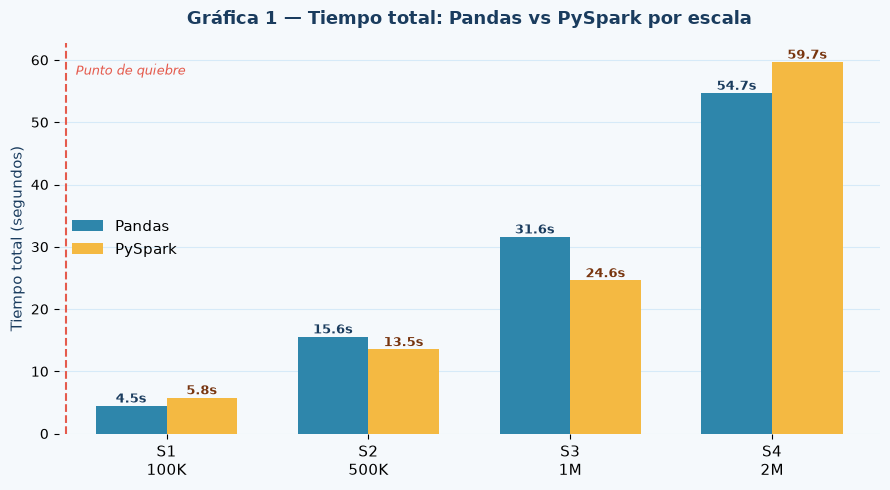

📌 ¿En qué escala PySpark empieza a ganar? ¿Coincide con tu hipótesis?


In [30]:
# ── Paso 5.2: GRÁFICA 1 — Tiempo total Pandas vs PySpark ─────────────────
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor(C_BG)
ax.set_facecolor(C_BG)

x  = range(len(escalas_labels))
bw = 0.35

bars1 = ax.bar([i - bw/2 for i in x], t_pandas, bw,
               color=C_PANDAS, label="Pandas", zorder=3)
bars2 = ax.bar([i + bw/2 for i in x], t_spark,  bw,
               color=C_SPARK,  label="PySpark", zorder=3)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{bar.get_height():.1f}s", ha="center", va="bottom",
            fontsize=9, color=C_NAVY, fontweight="bold")
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{bar.get_height():.1f}s", ha="center", va="bottom",
            fontsize=9, color="#78350F", fontweight="bold")

ax.set_xticks(list(x))
ax.set_xticklabels(escalas_labels, fontsize=11)
ax.set_ylabel("Tiempo total (segundos)", fontsize=11, color=C_NAVY)
ax.set_title("Gráfica 1 — Tiempo total: Pandas vs PySpark por escala",
             fontsize=13, color=C_NAVY, pad=14, fontweight="bold")
ax.yaxis.grid(True, color=C_GRID, zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right","left","bottom"]].set_visible(False)
ax.legend(fontsize=11, framealpha=0)

# Anotación del punto de quiebre
diffs = [p - s for p, s in zip(t_pandas, t_spark)]
idx_quiebre = next((i for i, d in enumerate(diffs) if d < 0), None)
if idx_quiebre is not None:
    ax.axvline(x=idx_quiebre - 0.5, color="#E55B4D", linestyle="--",
               linewidth=1.5, label="Punto de quiebre")
    ax.text(idx_quiebre - 0.45, ax.get_ylim()[1] * 0.92,
            "Punto de quiebre", color="#E55B4D", fontsize=9, fontstyle="italic")

plt.tight_layout()
plt.savefig("grafica1_tiempo_total.png", dpi=150, bbox_inches="tight",
            facecolor=C_BG)
plt.show()
print("📌 ¿En qué escala PySpark empieza a ganar? ¿Coincide con tu hipótesis?")


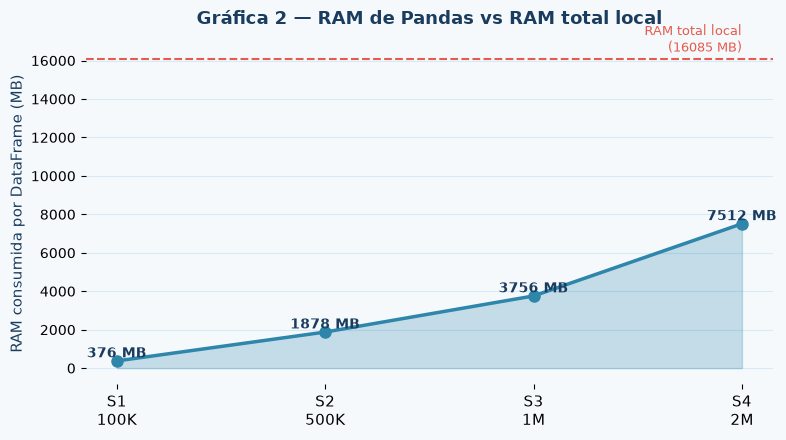

📌 ¿En qué escala el DataFrame de Pandas empieza a comprometer la RAM disponible?


In [31]:
# ── Paso 5.3: GRÁFICA 2 — RAM del DataFrame Pandas por escala ────────────
fig, ax = plt.subplots(figsize=(8, 4.5))
fig.patch.set_facecolor(C_BG)
ax.set_facecolor(C_BG)

ax.fill_between(range(len(escalas_labels)), ram_df,
                color=C_PANDAS, alpha=0.25)
ax.plot(range(len(escalas_labels)), ram_df,
        color=C_PANDAS, linewidth=2.5, marker="o", markersize=8, zorder=3)

for i, v in enumerate(ram_df):
    ax.text(i, v + max(ram_df)*0.025, f"{v:.0f} MB",
            ha="center", fontsize=10, color=C_NAVY, fontweight="bold")

# Línea de RAM disponible
ram_disponible = psutil.virtual_memory().total / 1024**2
ax.axhline(y=ram_disponible, color="#E55B4D", linestyle="--", linewidth=1.5)
ax.text(len(escalas_labels)-1, ram_disponible * 1.01,
        f"RAM total local\n({ram_disponible:.0f} MB)",
        ha="right", va="bottom", color="#E55B4D", fontsize=9)

ax.set_xticks(range(len(escalas_labels)))
ax.set_xticklabels(escalas_labels, fontsize=11)
ax.set_ylabel("RAM consumida por DataFrame (MB)", fontsize=11, color=C_NAVY)
ax.set_title("Gráfica 2 — RAM de Pandas vs RAM total local",
             fontsize=13, color=C_NAVY, pad=14, fontweight="bold")
ax.yaxis.grid(True, color=C_GRID, zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right","left","bottom"]].set_visible(False)

plt.tight_layout()
plt.savefig("grafica2_ram_pandas.png", dpi=150, bbox_inches="tight",
            facecolor=C_BG)
plt.show()
print("📌 ¿En qué escala el DataFrame de Pandas empieza a comprometer la RAM disponible?")


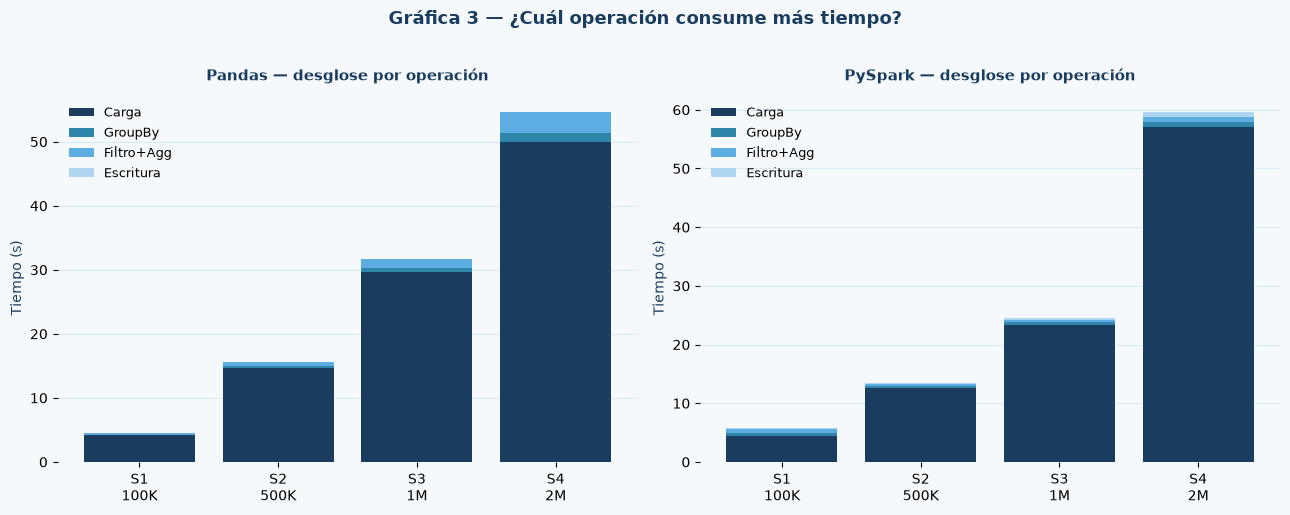

📌 ¿Qué operación domina en Pandas? ¿Y en PySpark? ¿Por qué difieren?


In [32]:
# ── Paso 5.4: GRÁFICA 3 — Desglose por operación (stacked bar) ───────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
fig.patch.set_facecolor(C_BG)

op_colors = ["#1A3C5E", "#2E86AB", "#5DADE2", "#AED6F1"]
ops = list(t_pandas_ops.keys())

for ax, ops_dict, title, base_color in [
    (axes[0], t_pandas_ops, "Pandas — desglose por operación", C_PANDAS),
    (axes[1], t_spark_ops,  "PySpark — desglose por operación", C_SPARK),
]:
    ax.set_facecolor(C_BG)
    bottom = [0] * len(escalas_labels)
    for op, color in zip(ops, op_colors):
        vals = ops_dict[op]
        ax.bar(escalas_labels, vals, bottom=bottom,
               label=op, color=color, zorder=3)
        bottom = [b + v for b, v in zip(bottom, vals)]
    ax.set_title(title, fontsize=11, color=C_NAVY, fontweight="bold", pad=10)
    ax.yaxis.grid(True, color=C_GRID, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top","right","left","bottom"]].set_visible(False)
    ax.set_ylabel("Tiempo (s)", fontsize=10, color=C_NAVY)
    ax.legend(fontsize=9, framealpha=0)

plt.suptitle("Gráfica 3 — ¿Cuál operación consume más tiempo?",
             fontsize=13, color=C_NAVY, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("grafica3_desglose_operaciones.png", dpi=150,
            bbox_inches="tight", facecolor=C_BG)
plt.show()
print("📌 ¿Qué operación domina en Pandas? ¿Y en PySpark? ¿Por qué difieren?")


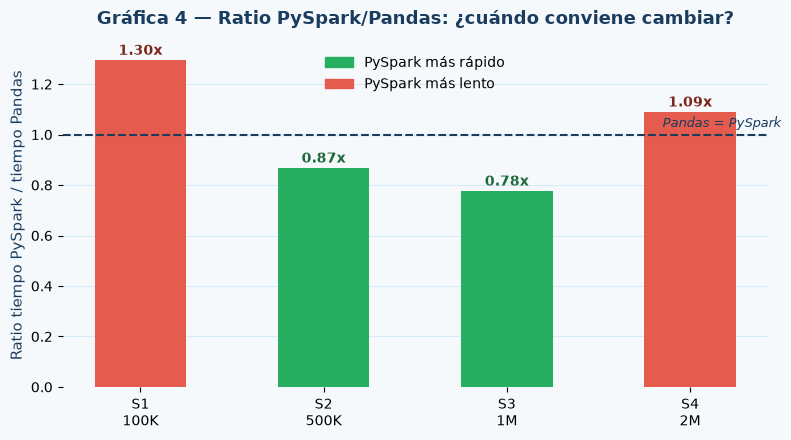

📌 Ratio < 1.0 significa que PySpark ganó. ¿En qué escala ocurre?


In [33]:
# ── Paso 5.5: GRÁFICA 4 — Ratio de velocidad PySpark / Pandas ─────────────
fig, ax = plt.subplots(figsize=(8, 4.5))
fig.patch.set_facecolor(C_BG)
ax.set_facecolor(C_BG)

ratios = [s / p if p > 0 else 0 for p, s in zip(t_pandas, t_spark)]
colores = ["#E55B4D" if r > 1 else "#27AE60" for r in ratios]

bars = ax.bar(escalas_labels, ratios, color=colores, zorder=3, width=0.5)
ax.axhline(y=1.0, color=C_NAVY, linestyle="--", linewidth=1.5, zorder=4)
ax.text(len(escalas_labels)-0.5, 1.03,
        "Pandas = PySpark", ha="right", fontsize=9,
        color=C_NAVY, fontstyle="italic")

for bar, r in zip(bars, ratios):
    label = f"{r:.2f}x"
    note  = "PySpark más lento" if r > 1 else "PySpark más rápido"
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.02,
            label, ha="center", fontsize=10, fontweight="bold",
            color="#7B241C" if r > 1 else "#1D6A39")

verde_p = mpatches.Patch(color="#27AE60", label="PySpark más rápido")
rojo_p  = mpatches.Patch(color="#E55B4D", label="PySpark más lento")
ax.legend(handles=[verde_p, rojo_p], fontsize=10, framealpha=0)

ax.set_ylabel("Ratio tiempo PySpark / tiempo Pandas", fontsize=11, color=C_NAVY)
ax.set_title("Gráfica 4 — Ratio PySpark/Pandas: ¿cuándo conviene cambiar?",
             fontsize=13, color=C_NAVY, pad=14, fontweight="bold")
ax.yaxis.grid(True, color=C_GRID, zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right","left","bottom"]].set_visible(False)

plt.tight_layout()
plt.savefig("grafica4_ratio.png", dpi=150, bbox_inches="tight",
            facecolor=C_BG)
plt.show()
print("📌 Ratio < 1.0 significa que PySpark ganó. ¿En qué escala ocurre?")


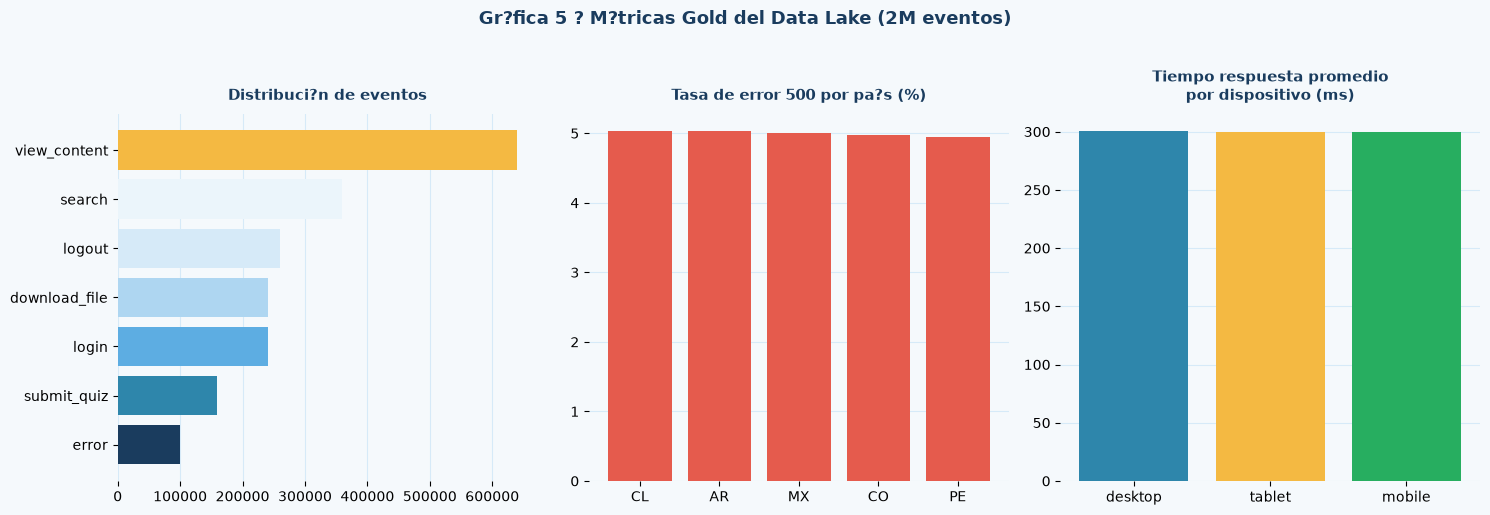

?? Estas m?tricas son el producto final del pipeline. Vinieron de 2M eventos raw.


In [34]:
# ?? Paso 5.6: GR?FICA 5 ? M?tricas Gold del Data Lake (2M eventos) ????????
# Convertir Gold a Pandas solo para visualizar (son resultados peque?os)
df_dist  = read_parquet_local("data_lake/2m/gold/events/distribucion_eventos")
df_error = read_parquet_local("data_lake/2m/gold/events/tasa_error_pais")
df_resp  = read_parquet_local("data_lake/2m/gold/events/response_time_device")

df_dist  = df_dist.sort_values("total", ascending=True)
df_error = df_error.sort_values("tasa_error", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(C_BG)

palette = ["#1A3C5E","#2E86AB","#5DADE2","#AED6F1","#D6EAF8","#EBF5FB","#F4B942"]

# Subgr?fica 1: distribuci?n de eventos
ax = axes[0]; ax.set_facecolor(C_BG)
ax.barh(df_dist["event_type"], df_dist["total"],
        color=palette[:len(df_dist)], zorder=3)
ax.set_title("Distribuci?n de eventos", fontsize=11,
             color=C_NAVY, fontweight="bold", pad=10)
ax.xaxis.grid(True, color=C_GRID, zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right","left","bottom"]].set_visible(False)

# Subgr?fica 2: tasa de error por pa?s
ax = axes[1]; ax.set_facecolor(C_BG)
ax.bar(df_error["country"],
       df_error["tasa_error"].astype(float),
       color="#E55B4D", zorder=3)
ax.set_title("Tasa de error 500 por pa?s (%)", fontsize=11,
             color=C_NAVY, fontweight="bold", pad=10)
ax.yaxis.grid(True, color=C_GRID, zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right","left","bottom"]].set_visible(False)

# Subgr?fica 3: tiempo de respuesta por dispositivo
ax = axes[2]; ax.set_facecolor(C_BG)
ax.bar(df_resp["device"], df_resp["avg_response_ms"],
       color=["#2E86AB","#F4B942","#27AE60"], zorder=3)
ax.set_title("Tiempo respuesta promedio\npor dispositivo (ms)", fontsize=11,
             color=C_NAVY, fontweight="bold", pad=10)
ax.yaxis.grid(True, color=C_GRID, zorder=0)
ax.set_axisbelow(True)
ax.spines[["top","right","left","bottom"]].set_visible(False)

plt.suptitle("Gr?fica 5 ? M?tricas Gold del Data Lake (2M eventos)",
             fontsize=13, color=C_NAVY, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("grafica5_gold_metricas.png", dpi=150,
            bbox_inches="tight", facecolor=C_BG)
plt.show()
print("?? Estas m?tricas son el producto final del pipeline. Vinieron de 2M eventos raw.")


---
## PARTE 6 · Reflexión guiada

El benchmark ya habló. Ahora te toca a ti interpretar los resultados.
Responde las siguientes preguntas basándote en **tus propios datos** del experimento.


In [35]:
# ── Paso 6.1: resumen comparativo final ──────────────────────────────────
print("═" * 65)
print("  RESUMEN FINAL DEL BENCHMARK")
print("═" * 65)
print(f"{'Escala':<18} {'Pandas (s)':>12} {'PySpark (s)':>13} {'Ratio':>8} {'Ganador':>10}")
print("─" * 65)
for nombre in nombres:
    p = resultados_pandas[nombre]["total_s"]
    s = resultados_spark[nombre]["total_s"]
    r = s / p if p > 0 else 0
    ganador = "PySpark ✅" if s < p else "Pandas  ✅"
    print(f"  {nombre:<16} {p:>12.2f} {s:>13.2f} {r:>7.2f}x {ganador:>10}")
print("═" * 65)
print()
print(f"  RAM DataFrame Pandas (S4/2M): {resultados_pandas[nombres[-1]]['ram_df_mb']:.0f} MB")
print(f"  RAM total disponible local  : {psutil.virtual_memory().total/1024**2:.0f} MB")
print(f"  Porcentaje ocupado (S4)     : "
      f"{resultados_pandas[nombres[-1]]['ram_df_mb']/psutil.virtual_memory().total*1024**2*100:.1f}%")


═════════════════════════════════════════════════════════════════
  RESUMEN FINAL DEL BENCHMARK
═════════════════════════════════════════════════════════════════
Escala               Pandas (s)   PySpark (s)    Ratio    Ganador
─────────────────────────────────────────────────────────────────
  S1 · 1M                  4.46          5.78    1.30x  Pandas  ✅
  S2 · 5M                 15.56         13.52    0.87x  PySpark ✅
  S3 · 10M                31.61         24.59    0.78x  PySpark ✅
  S4 · 20M                54.68         59.67    1.09x  Pandas  ✅
═════════════════════════════════════════════════════════════════

  RAM DataFrame Pandas (S4/2M): 7512 MB
  RAM total disponible local  : 16085 MB
  Porcentaje ocupado (S4)     : 46.7%


---

## Paso 7 ? Stress test final con 6M eventos

Este bloque fuerza una escala mayor para que la diferencia entre trabajar con un DataFrame local y usar Spark sea m?s evidente en una presentaci?n o defensa t?cnica.


????????????????????????????????????????????????????????????????????????
  PASO 7 ? STRESS TEST FINAL
????????????????????????????????????????????????????????????????????????
Escala seleccionada: 10,000,000 eventos
Carpeta destino    : data_lake/10m
Este bloque puede tardar bastante m?s que S4/2M.
????????????????????????????????????????????????????????????????????????

? Pandas stress (10,000,000 eventos) ...
? Pandas completado: 38.87s | RAM DF: 3756 MB

? PySpark stress (10,000,000 eventos) ...
? PySpark completado: 31.41s

RESUMEN STRESS TEST 6M
  Motor  Eventos  Tiempo total (s)  RAM DataFrame (MB) Estado
 Pandas 10000000            38.874             3755.79     OK
PySpark 10000000            31.413                 NaN     OK

????????????????????????????????????????????????????????????????????????
Ganador en stress test: PySpark
Ratio PySpark/Pandas  : 0.81x
RAM Pandas / RAM local: 3756 MB / 16085 MB
????????????????????????????????????????????????????????????????????????


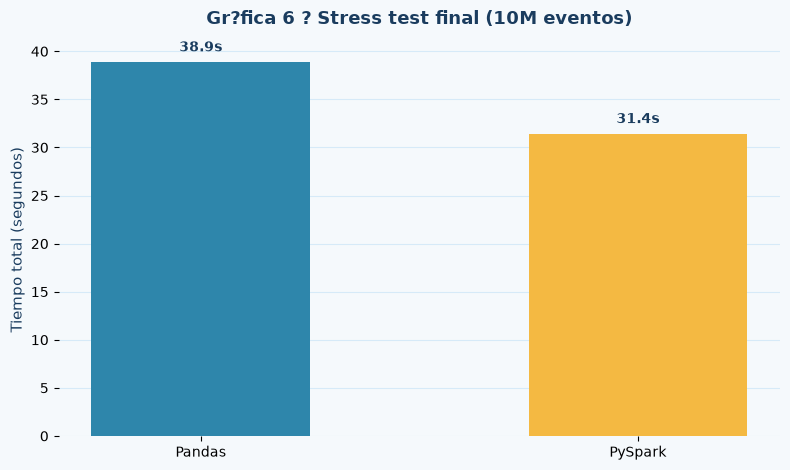

?? Esta escala funciona como cierre vendedor: muestra qu? ocurre cuando el volumen ya no es c?modo para un DataFrame local.


In [36]:
# ?? Paso 7.1: benchmark de stress con 6M eventos ?????????????????????????
# Puede tardar varios minutos. Para una prueba r?pida desde consola puedes usar:
# $env:STRESS_N="100000" antes de ejecutar nbconvert.

import os, gc
from pathlib import Path

STRESS_N = int(os.environ.get("STRESS_N", "10000000"))
STRESS_TAG = f"{STRESS_N // 1_000_000}m" if STRESS_N % 1_000_000 == 0 else f"{STRESS_N // 1000}k"
STRESS_LABEL = f"{STRESS_N:,} eventos"

print("?" * 72)
print("  PASO 7 ? STRESS TEST FINAL")
print("?" * 72)
print(f"Escala seleccionada: {STRESS_LABEL}")
print(f"Carpeta destino    : data_lake/{STRESS_TAG}")
print("Este bloque puede tardar bastante m?s que S4/2M.")
print("?" * 72)

stress_pandas = None
stress_spark = None
stress_errors = []

try:
    print(f"\n? Pandas stress ({STRESS_LABEL}) ...", flush=True)
    stress_pandas = benchmark_pandas(STRESS_N, STRESS_TAG)
    print(f"? Pandas completado: {stress_pandas['total_s']:.2f}s | RAM DF: {stress_pandas['ram_df_mb']:.0f} MB")
except Exception as exc:
    stress_errors.append(("Pandas", type(exc).__name__, str(exc)))
    print(f"?? Pandas no complet? el stress test: {type(exc).__name__}: {exc}")

gc.collect()

csv_stress = Path("data_lake") / STRESS_TAG / "bronze" / "events" / "logs.csv"
if csv_stress.exists():
    try:
        print(f"\n? PySpark stress ({STRESS_LABEL}) ...", flush=True)
        stress_spark = benchmark_pyspark(STRESS_N, STRESS_TAG)
        print(f"? PySpark completado: {stress_spark['total_s']:.2f}s")
    except Exception as exc:
        stress_errors.append(("PySpark", type(exc).__name__, str(exc)))
        print(f"?? PySpark no complet? el stress test: {type(exc).__name__}: {exc}")
else:
    stress_errors.append(("PySpark", "Sin CSV Bronze", f"No existe {csv_stress}"))
    print(f"?? No se ejecuta PySpark porque no existe {csv_stress}")

rows = []
if stress_pandas:
    rows.append({
        "Motor": "Pandas",
        "Eventos": STRESS_N,
        "Tiempo total (s)": stress_pandas["total_s"],
        "RAM DataFrame (MB)": stress_pandas.get("ram_df_mb", None),
        "Estado": "OK",
    })
if stress_spark:
    rows.append({
        "Motor": "PySpark",
        "Eventos": STRESS_N,
        "Tiempo total (s)": stress_spark["total_s"],
        "RAM DataFrame (MB)": None,
        "Estado": "OK",
    })
for motor, err, msg in stress_errors:
    rows.append({
        "Motor": motor,
        "Eventos": STRESS_N,
        "Tiempo total (s)": None,
        "RAM DataFrame (MB)": None,
        "Estado": f"{err}: {msg[:80]}",
    })

df_stress = pd.DataFrame(rows)
print("\nRESUMEN STRESS TEST 6M")
print(df_stress.to_string(index=False))

if stress_pandas and stress_spark and stress_pandas["total_s"] > 0:
    ratio_stress = stress_spark["total_s"] / stress_pandas["total_s"]
    ganador_stress = "PySpark" if stress_spark["total_s"] < stress_pandas["total_s"] else "Pandas"
    print("\n" + "?" * 72)
    print(f"Ganador en stress test: {ganador_stress}")
    print(f"Ratio PySpark/Pandas  : {ratio_stress:.2f}x")
    print(f"RAM Pandas / RAM local: {stress_pandas['ram_df_mb']:.0f} MB / {psutil.virtual_memory().total / 1024**2:.0f} MB")
    print("?" * 72)

if stress_pandas or stress_spark:
    fig, ax = plt.subplots(figsize=(8, 4.8))
    fig.patch.set_facecolor(C_BG)
    ax.set_facecolor(C_BG)

    motores = []
    tiempos = []
    colores = []
    if stress_pandas:
        motores.append("Pandas")
        tiempos.append(stress_pandas["total_s"])
        colores.append(C_PANDAS)
    if stress_spark:
        motores.append("PySpark")
        tiempos.append(stress_spark["total_s"])
        colores.append(C_SPARK)

    bars = ax.bar(motores, tiempos, color=colores, width=0.5, zorder=3)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(tiempos)*0.02,
                f"{bar.get_height():.1f}s", ha="center", va="bottom",
                fontsize=10, color=C_NAVY, fontweight="bold")

    ax.set_ylabel("Tiempo total (segundos)", fontsize=11, color=C_NAVY)
    ax.set_title(f"Gr?fica 6 ? Stress test final ({STRESS_N/1_000_000:.0f}M eventos)",
                 fontsize=13, color=C_NAVY, pad=14, fontweight="bold")
    ax.yaxis.grid(True, color=C_GRID, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top","right","left","bottom"]].set_visible(False)

    plt.tight_layout()
    plt.savefig("grafica6_stress_6m.png", dpi=150, bbox_inches="tight", facecolor=C_BG)
    plt.show()
    print("?? Esta escala funciona como cierre vendedor: muestra qu? ocurre cuando el volumen ya no es c?modo para un DataFrame local.")
else:
    print("\nNo se pudo generar gr?fica porque ning?n motor complet? el stress test.")


---
### ✏️ Preguntas de reflexión final

*(Doble clic en cada celda para responder)*


**1. ¿En qué escala PySpark comenzó a superar a Pandas en tiempo total? ¿Qué explica esa transición?**

*Tu respuesta:*


**2. La Gráfica 2 muestra cuánta RAM consume el DataFrame de Pandas. ¿Qué pasaría si tu organización manejara 50M de eventos diarios en un servidor con 16 GB de RAM?**

*Tu respuesta:*


**3. ¿Por qué en la escala S1 (100K eventos) PySpark fue más lento que Pandas? ¿Ese overhead es un defecto de PySpark?**

*Tu respuesta:*


**4. Compara el tamaño en disco del CSV Bronze vs el Parquet Silver (Paso 4.3). ¿Cuánto espacio ahorró el formato Parquet? ¿Por qué es relevante en un Data Lake de producción?**

*Tu respuesta:*


**5. Diseña un escenario real (universidad, empresa, hospital, gobierno) donde usarías exclusivamente Pandas, y otro donde necesitarías obligatoriamente PySpark. Justifica ambas decisiones con los datos de este experimento.**

*Tu respuesta:*


---
## 🏁 Cierre del laboratorio

### Lo que construiste hoy

| Componente | Resultado |
|---|---|
| Dataset generado | 4 escalas: 100K, 500K, 1M, 2M eventos |
| Benchmark Pandas | 4 operaciones × 4 escalas medidas |
| Benchmark PySpark | 4 operaciones × 4 escalas medidas |
| Data Lake construido | Bronze → Silver (Parquet) → Gold (5 métricas) |
| Hadoop utilizado | Inspección de rutas, particiones y tamaños |
| Gráficas generadas | 5 visualizaciones basadas en tus propios datos |

### La idea central que el benchmark demostró

> **Pandas ayuda a explorar. PySpark ayuda a escalar.**
> No son herramientas competidoras: son herramientas para escalas distintas.
> El punto de quiebre depende de tu hardware, tu dataset y tu operación.
> En este experimento, lo mediste tú mismo.

---
*Semana 05 — Big Data · UNAJ · Docente: Leibnihtz Abrahan Ayamamani Choque · 2026-I*
